In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

print("Starting full training for 30 epochs...")
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

print("Full training finished successfully!")

Starting full training for 30 epochs...
Epoch 1/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step - loss: 0.0050 - val_loss: 0.0054
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - loss: 0.0079 - val_loss: 0.0152
Epoch 3/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - loss: 0.0123 - val_loss: 0.0057
Epoch 4/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - loss: 0.0108 - val_loss: 0.0099
Epoch 5/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0099 - val_loss: 0.0060
Epoch 6/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - loss: 0.0033 - val_loss: 0.0050
Epoch 7/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - loss: 0.0015 - val_loss: 0.0044
Epoch 8/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0012 - val_loss: 0.0043
Epoch 9/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 8s 106ms/step - loss: 0.0012 - val_loss: 0.0040
Epoch 10/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.0011 - val_loss: 0.0052
Epoch 11/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - loss: 0.0011 - val_loss: 0.0043
Epoch 12/30
60/60 ━━━

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
EVALUATION METRICS:
Mean Absolute Error (MAE): $595.07
Root Mean Squared Error (RMSE): $708.58
Mean Absolute Percentage Error (MAPE): 14.49%


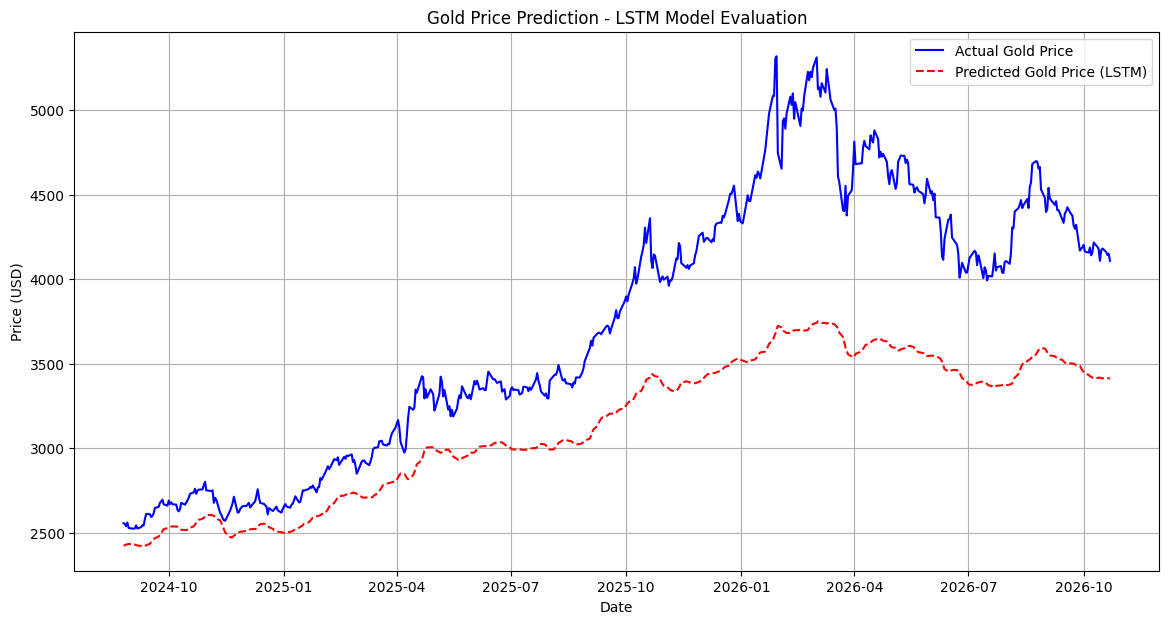

In [7]:

predictions_scaled = model.predict(X_test)

predictions = scaler.inverse_transform(predictions_scaled)
y_test_original = scaler.inverse_transform(y_test.reshape(-1, 1))

mae = mean_absolute_error(y_test_original, predictions)
rmse = np.sqrt(mean_squared_error(y_test_original, predictions))
mape = np.mean(np.abs((y_test_original - predictions) / y_test_original)) * 100

print("EVALUATION METRICS:")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

plt.figure(figsize=(14, 7))
plt.plot(test_dates, y_test_original, label="Actual Gold Price", color="blue")
plt.plot(test_dates, predictions, label="Predicted Gold Price (LSTM)", color="red", linestyle="--")
plt.title("Gold Price Prediction - LSTM Model Evaluation")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [2]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

START_DATE = "2016-01-01"
END_DATE = "2026-10-23"  # End date is exclusive

raw = yf.download(
    "GC=F",
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)

if raw.empty or "Close" not in raw.columns:
    raise ValueError(
        "Gold data download failed. Check internet connection and rerun."
    )

df = raw[["Close"]].rename(columns={"Close": "Gold_Price"})
df.index = pd.to_datetime(df.index)
df = df[~df.index.duplicated(keep="last")].sort_index()

df["Gold_Price"] = pd.to_numeric(df["Gold_Price"], errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["Gold_Price"])
df = df[df["Gold_Price"] > 0]

if len(df) < 500:
    raise ValueError("Not enough historical records for this project.")

print("TASK 1 COMPLETED")
print("Number of records:", len(df))
print("First available date:", df.index.min().date())
print("Last available date:", df.index.max().date())
print("Missing values:", df["Gold_Price"].isna().sum())

display(df.head())
display(df.tail())


TASK 1 COMPLETED
Number of records: 2717
First available date: 2016-01-04
Last available date: 2026-10-22
Missing values: 0


Price,Gold_Price
Date,
2016-01-04,1075.099976
2016-01-05,1078.400024
2016-01-06,1091.900024
2016-01-07,1107.699951
2016-01-08,1097.800049


Price,Gold_Price
Date,
2026-10-16,4181.100098
2026-10-19,4160.100098
2026-10-20,4142.600098
2026-10-21,4150.000000
2026-10-22,4107.799805


In [4]:

prices = df["Gold_Price"].values.reshape(-1, 1)

LOOKBACK = 60
split_index = int(len(prices) * 0.80)

# Fit scaler on training data only
scaler = MinMaxScaler()
scaler.fit(prices[:split_index])

scaled_prices = scaler.transform(prices)

X_all, y_all, target_indices = [], [], []

for i in range(LOOKBACK, len(scaled_prices)):
    X_all.append(scaled_prices[i-LOOKBACK:i, 0])
    y_all.append(scaled_prices[i, 0])
    target_indices.append(i)

X_all = np.asarray(X_all, dtype=np.float32).reshape(-1, LOOKBACK, 1)
y_all = np.asarray(y_all, dtype=np.float32)
target_indices = np.asarray(target_indices)

train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

test_dates = df.index[target_indices[test_mask]]

print("TASK 2 COMPLETED")
print("Sequence length:", LOOKBACK, "trading days")
print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)


TASK 2 COMPLETED
Sequence length: 60 trading days
Training sequences: (2113, 60, 1)
Testing sequences: (544, 60, 1)


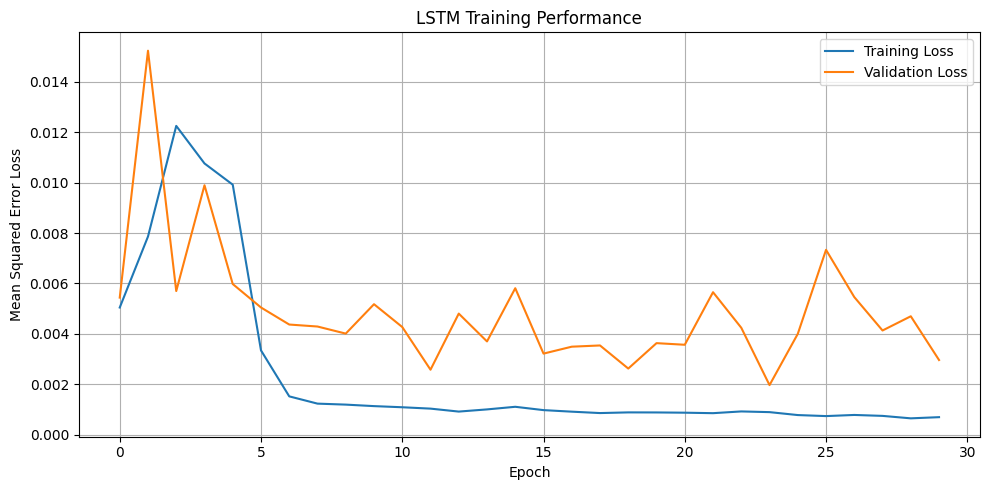

In [8]:

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [9]:

predicted_scaled = model.predict(X_test, verbose=0)

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

predicted_prices = scaler.inverse_transform(
    predicted_scaled
).ravel()

mae = mean_absolute_error(actual_prices, predicted_prices)
rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))

mape = np.mean(
    np.abs((actual_prices - predicted_prices) / actual_prices)
) * 100

approx_accuracy = max(0, 100 - mape)

print("TASK 4 COMPLETED: MODEL EVALUATION")
print("-" * 40)
print(f"MAE:  ${mae:.2f} per troy ounce")
print(f"RMSE: ${rmse:.2f} per troy ounce")
print(f"MAPE: {mape:.2f}%")
print(f"Approx. 100 - MAPE indicator: {approx_accuracy:.2f}%")
print("-" * 40)
print("Note: The percentage is an error-based indicator,")
print("not a guaranteed or standard prediction accuracy.")


TASK 4 COMPLETED: MODEL EVALUATION
----------------------------------------
MAE:  $595.07 per troy ounce
RMSE: $708.58 per troy ounce
MAPE: 14.49%
Approx. 100 - MAPE indicator: 85.51%
----------------------------------------
Note: The percentage is an error-based indicator,
not a guaranteed or standard prediction accuracy.


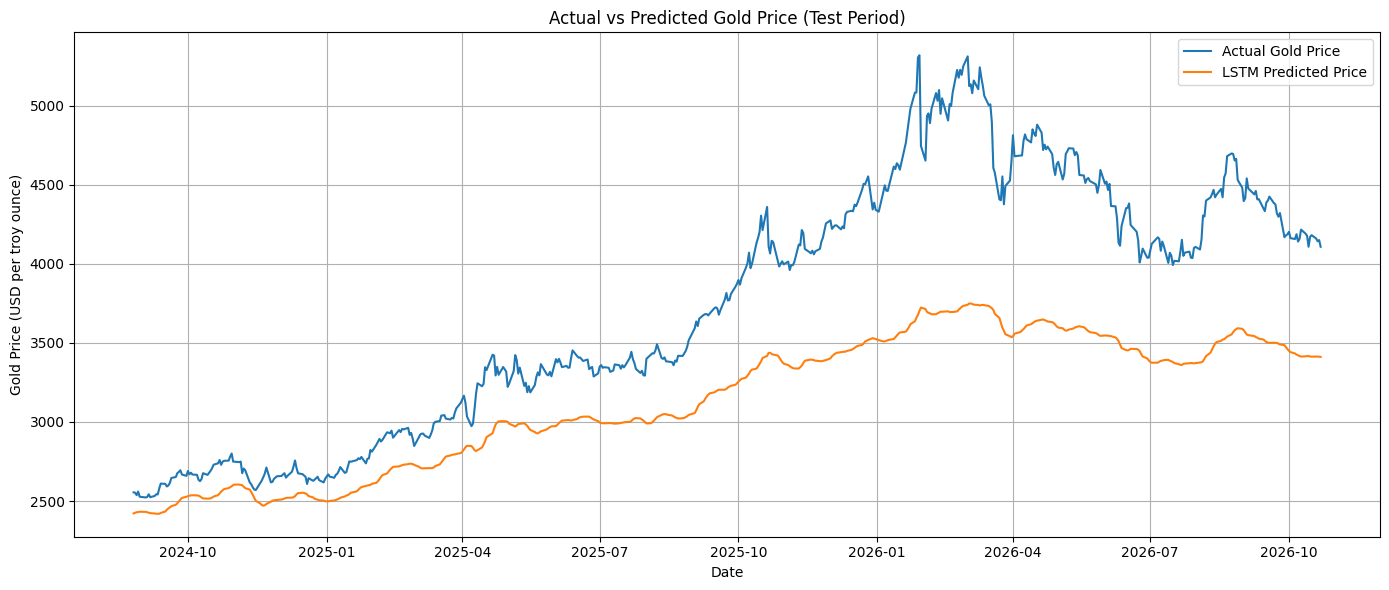

In [10]:

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates, actual_prices,
    label="Actual Gold Price"
)
plt.plot(
    test_dates, predicted_prices,
    label="LSTM Predicted Price"
)

plt.title("Actual vs Predicted Gold Price (Test Period)")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD per troy ounce)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [11]:

comparison = pd.DataFrame({
    "Date": test_dates,
    "Actual_Price": actual_prices,
    "Predicted_Price": predicted_prices
})

comparison["Absolute_Error"] = np.abs(
    comparison["Actual_Price"] - comparison["Predicted_Price"]
)

print("Sample predictions on unseen historical test dates:")
display(comparison.head(15).round(2))


Sample predictions on unseen historical test dates:


,Date,Actual_Price,Predicted_Price,Absolute_Error
0,2024-08-26,2555.199951,2422.120117,133.080002
1,2024-08-27,2552.899902,2426.139893,126.760002
2,2024-08-28,2537.800049,2429.500000,108.300003
3,2024-08-29,2560.300049,2430.689941,129.610001
4,2024-08-30,2527.600098,2432.770020,94.830002
5,2024-09-03,2523.000000,2431.770020,91.230003
6,2024-09-04,2526.000000,2428.949951,97.050003
7,2024-09-05,2543.100098,2425.639893,117.459999
8,2024-09-06,2524.600098,2423.969971,100.629997
9,2024-09-09,2532.699951,2421.510010,111.190002


NEXT 30 BUSINESS-DAY FORECAST


,Date,Predicted_Gold_Price_USD_per_ounce
0,2026-10-23,3407.88
1,2026-10-26,3357.10
2,2026-10-27,3293.80
3,2026-10-28,3223.45
4,2026-10-29,3150.26
5,2026-10-30,3077.00
6,2026-11-02,3005.54
7,2026-11-03,2937.11
8,2026-11-04,2872.44
9,2026-11-05,2811.95


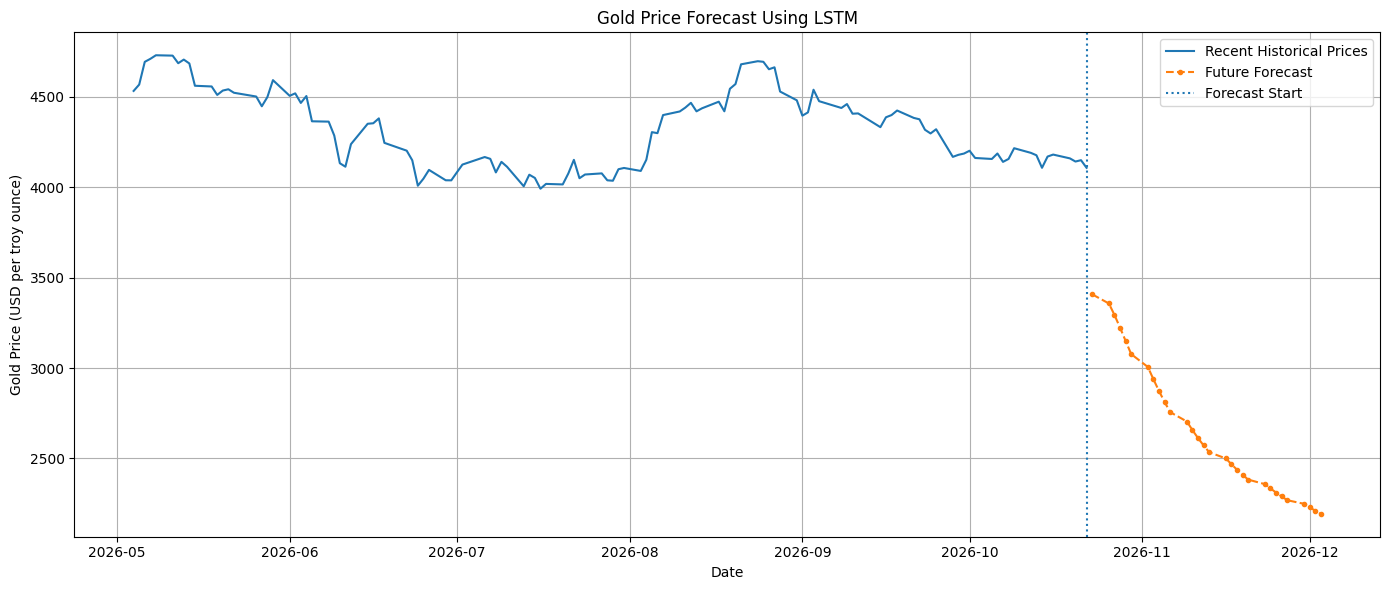

Forecast saved as gold_price_forecast.csv


In [12]:

last_sequence = scaled_prices[-LOOKBACK:, 0].copy()
future_scaled_predictions = []

for step in range(30):
    model_input = last_sequence.reshape(1, LOOKBACK, 1)

    next_scaled = float(model.predict(model_input, verbose=0)[0, 0])
    future_scaled_predictions.append(next_scaled)

    last_sequence = np.append(last_sequence[1:], next_scaled)

future_prices = scaler.inverse_transform(
    np.array(future_scaled_predictions).reshape(-1, 1)
).ravel()

future_dates = pd.bdate_range(
    start=df.index[-1] + pd.offsets.BDay(1),
    periods=30
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Gold_Price_USD_per_ounce": future_prices
})

print("NEXT 30 BUSINESS-DAY FORECAST")
display(forecast_df.round(2))

plt.figure(figsize=(14, 6))

plt.plot(
    df.index[-120:],
    df["Gold_Price"].iloc[-120:],
    label="Recent Historical Prices"
)

plt.plot(
    future_dates,
    future_prices,
    marker="o",
    markersize=3,
    linestyle="--",
    label="Future Forecast"
)

plt.axvline(
    df.index[-1],
    linestyle=":",
    label="Forecast Start"
)

plt.title("Gold Price Forecast Using LSTM")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD per troy ounce)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

forecast_df.to_csv("gold_price_forecast.csv", index=False)
print("Forecast saved as gold_price_forecast.csv")
